### **Data Preprocessing** : Wholesale Customers

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [74]:
df = pd.read_csv('../data/wholesale customers data.csv')

In [75]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [77]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [78]:
# checking for null values
df.isnull().sum()

### No missing values in the dataset.

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [79]:
# Checking for duplicates
df.duplicated().sum()

### No duplicate values in the dataset.

np.int64(0)

In [ ]:
# check outliers 
numeric_columns = df.select_dtypes(include=[int,float]).columns

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df < lower_bound) | (df > upper_bound)]
    print(f"Column: {col}, Outliers: {outliers[col].count()}")



Column: Channel, Outliers: 0
Column: Region, Outliers: 0
Column: Fresh, Outliers: 20
Column: Milk, Outliers: 28
Column: Grocery, Outliers: 24
Column: Frozen, Outliers: 43
Column: Detergents_Paper, Outliers: 30
Column: Delicassen, Outliers: 27


In [105]:
# drop useless columns
df.drop(['Channel', 'Region'], axis=1, inplace=True)

### EDA : Wholeshale Customer

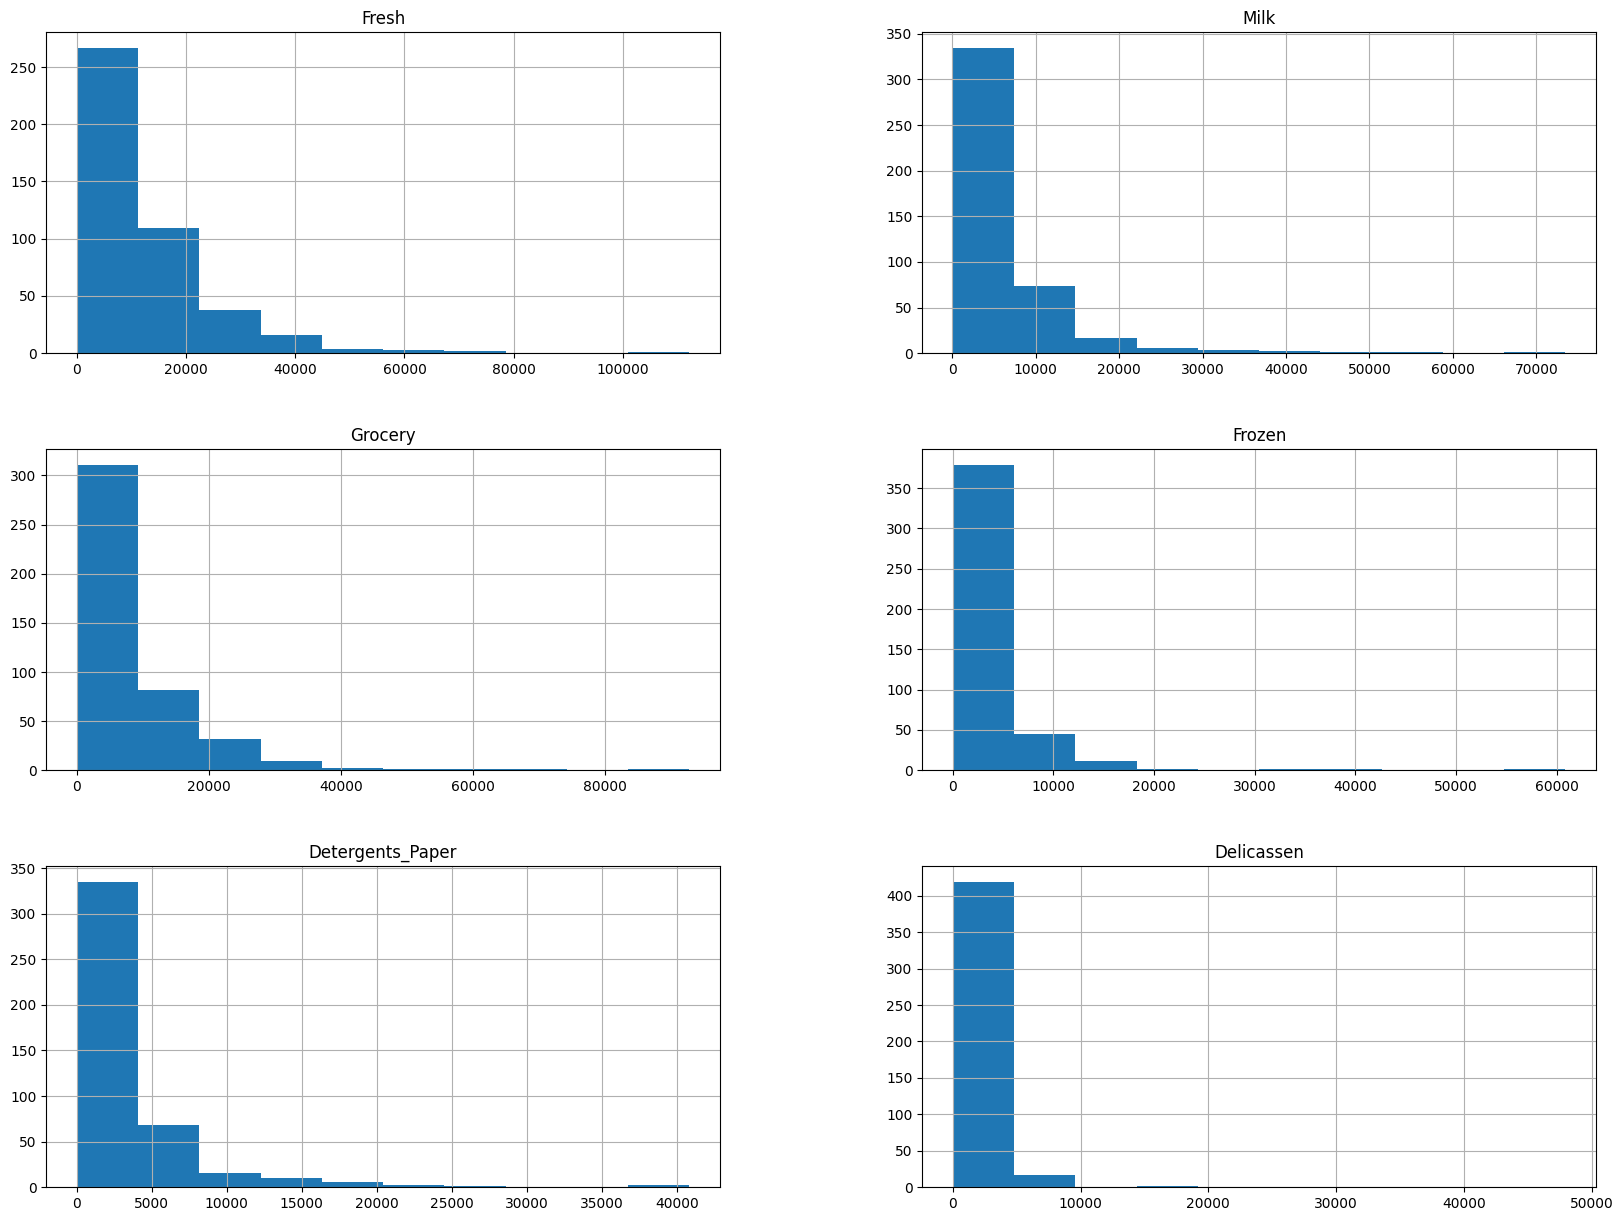

In [106]:
# Check feature distribution
df.hist(bins=10, figsize=(20,15))
plt.show()

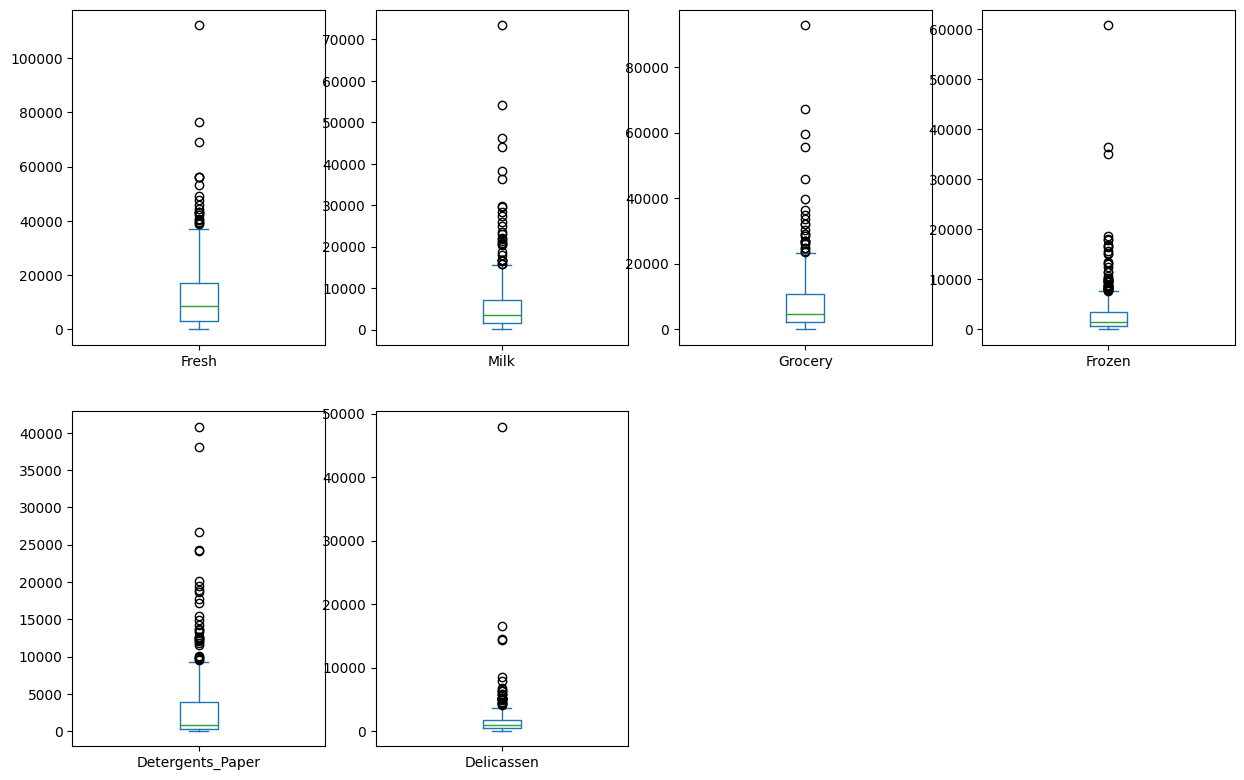

In [107]:
df.plot(kind='box', subplots=True, layout=(4,4), figsize=(15,20))
plt.show()

<Axes: >

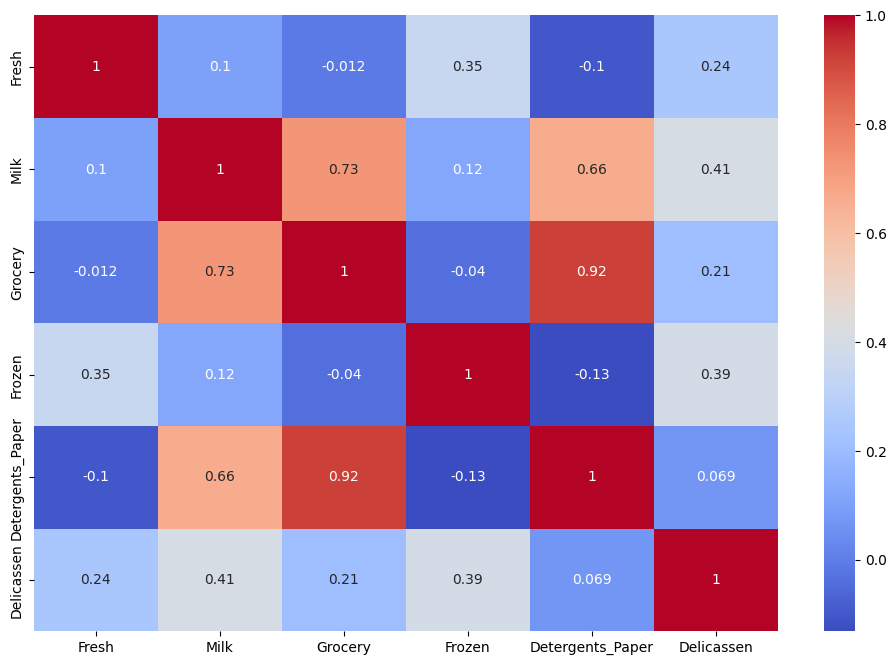

In [108]:
# correlation check
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [98]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

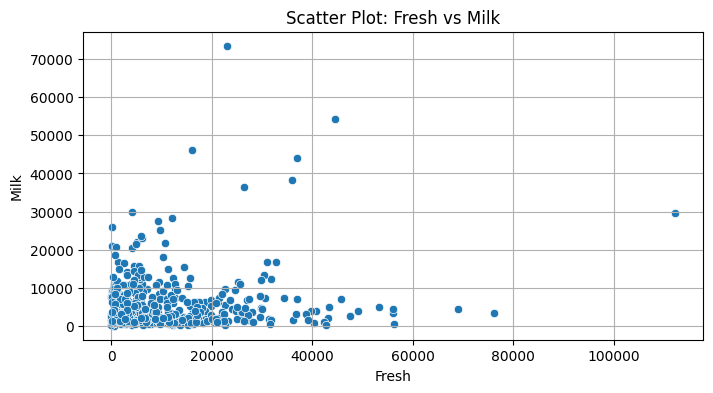

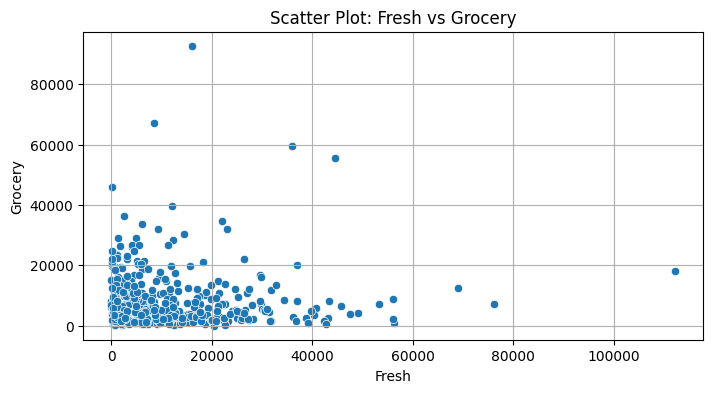

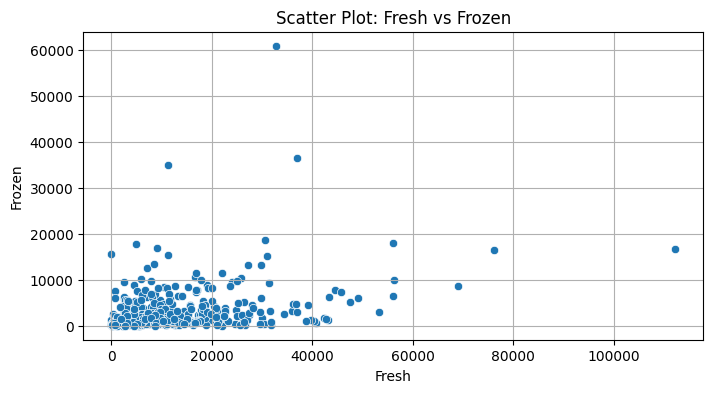

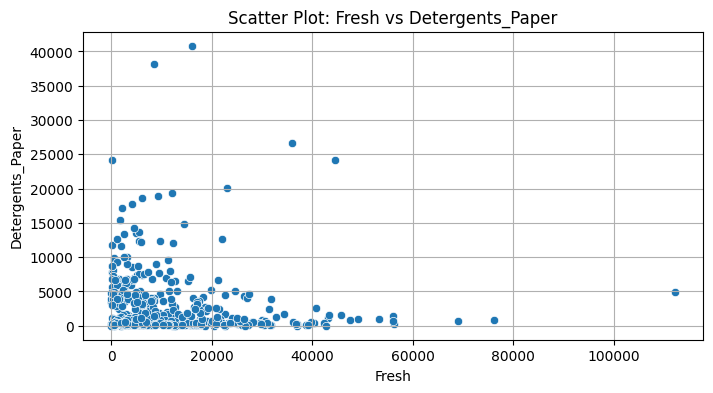

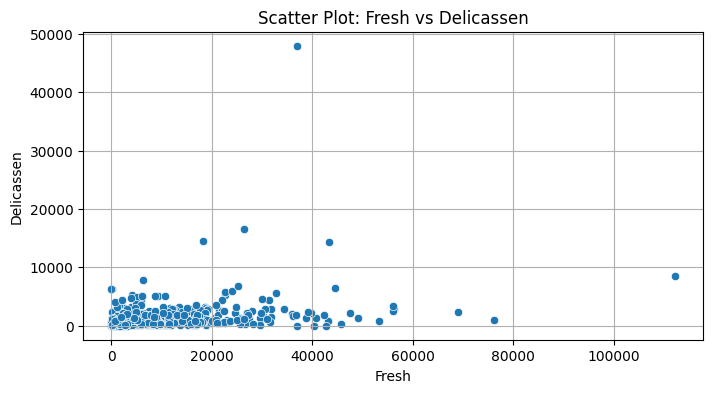

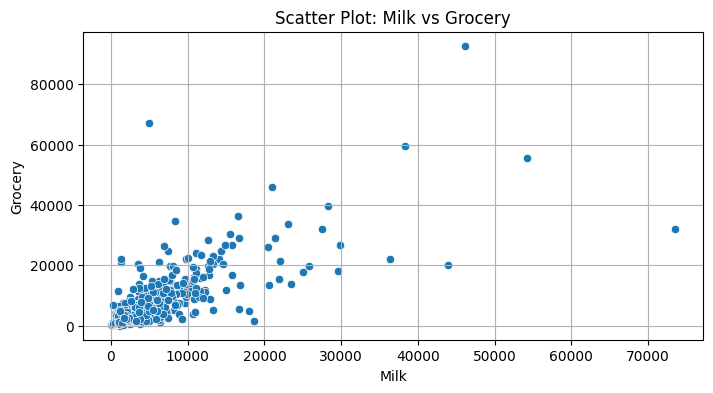

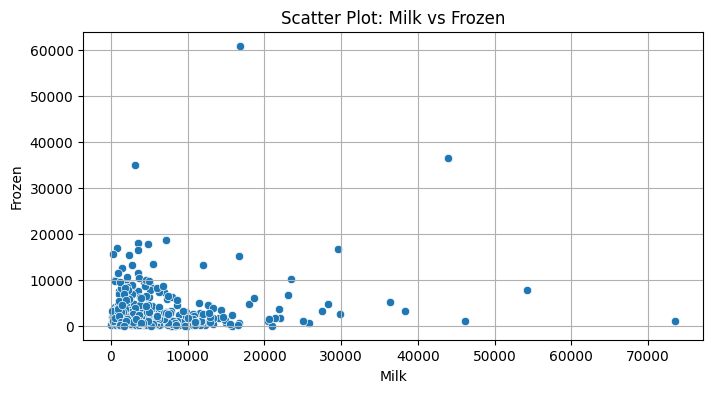

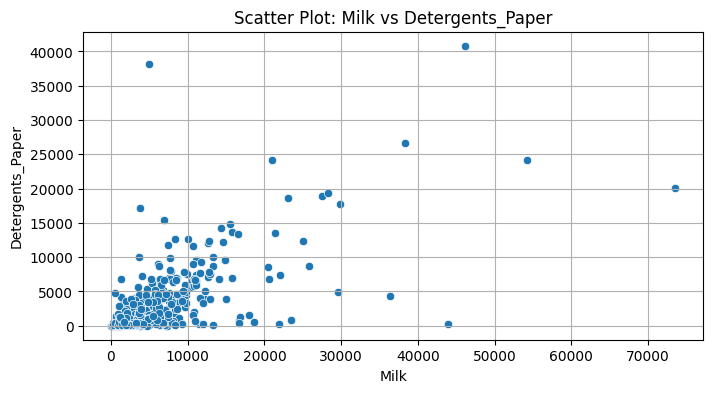

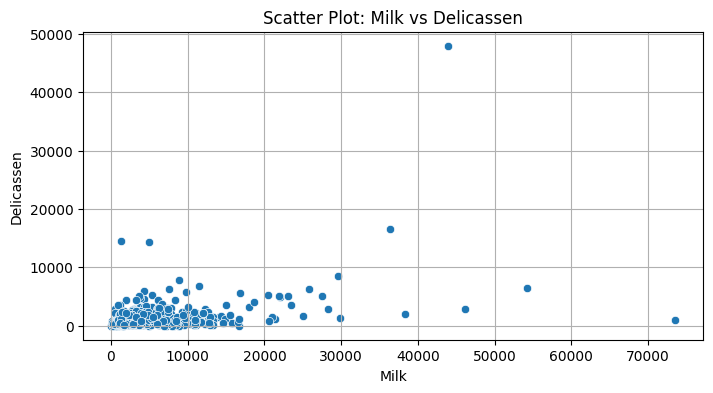

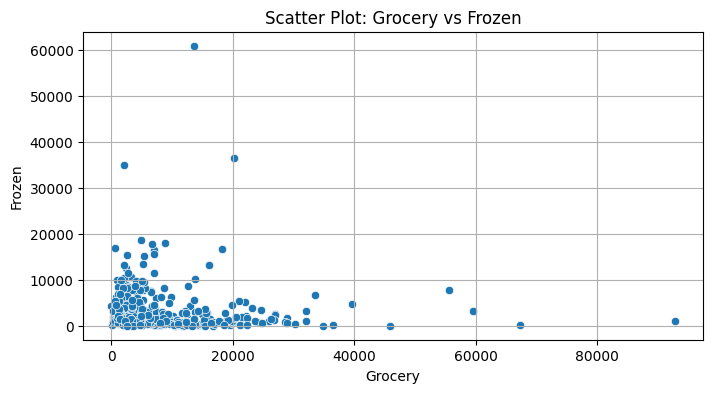

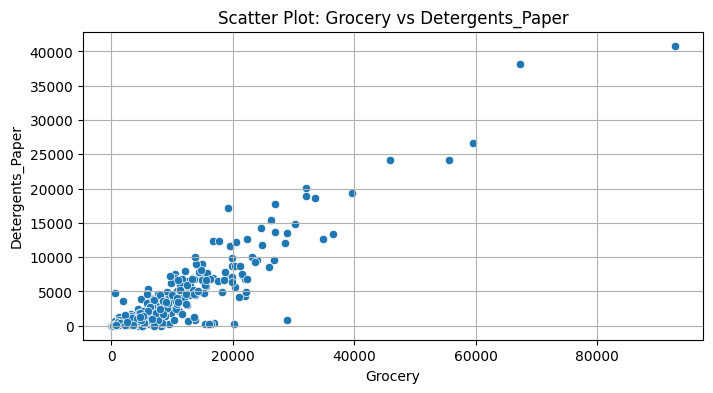

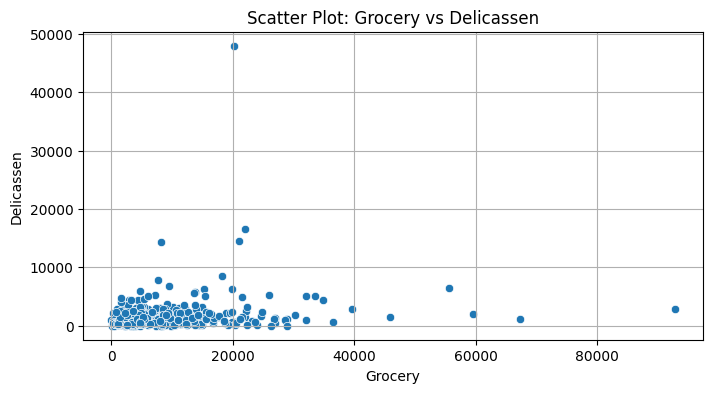

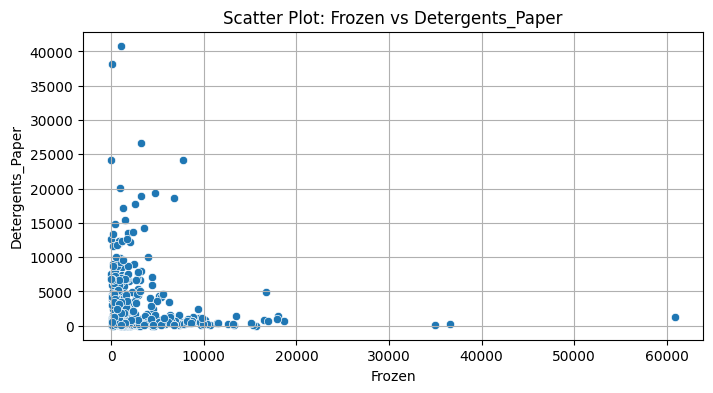

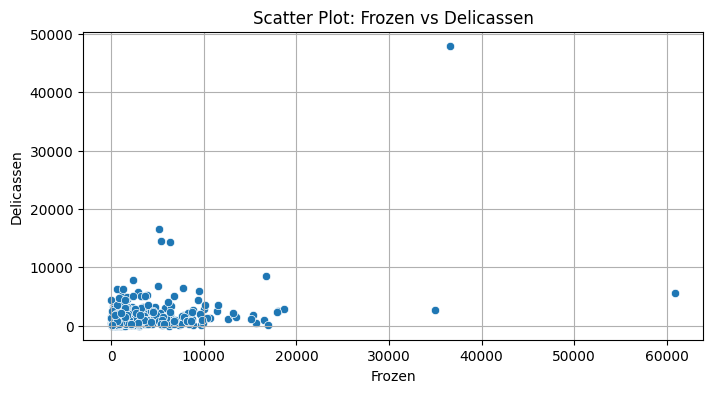

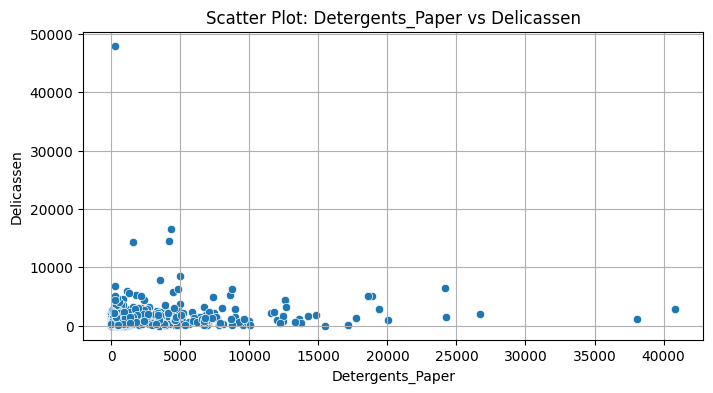

In [115]:
from itertools import combinations

numeric_cols = df.select_dtypes(include=[int,float]).columns

for col1, col2 in combinations(numeric_cols, 2):
    plt.figure(figsize=(8, 4))
    sns.scatterplot(data=df, x=col1, y=col2)
    
    plt.title(f'Scatter Plot: {col1} vs {col2}')
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.grid(True)
    plt.show()


In [117]:
# save dataset
df.to_csv('../data/wholesale_customers_cleaned.csv', index=False)